# **Data Collection**

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Path to dataset files: /kaggle/input/brain-tumor-mri-dataset


In [ ]:
import shutil

shutil.copytree(path, "dataset")

'dataset'

In [ ]:
# This cell is no longer needed as the paths are now defined in cell b5OULAznGqGr
# train_dataset = '/content/dataset/Training'
# test_dataset = '/content/dataset/Testing'

In [ ]:
# !pip install sympy==1.12

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 91.5 MB/s eta 0:00:00
ERROR: Operation cancelled by user
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/cli/base_command.py", line 179, in exc_logging_wrapper
    status = run_func(*args)
             ^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/cli/req_command.py", line 67, in wrapper
    return func(self, options, args)
           ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/commands/install.py", line 447, in run
    conflicts = self._determine_conflicts(to_install)
                ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/commands/install.py", line 578, in _determine_conflicts
    return check_install_conflicts(to_install)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/operations/check.p

In [ ]:
# !pip install torch torchvision timm scikit-learn matplotlib opencv-python


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.3/6.3 MB 27.5 MB/s eta 0:00:00
  Attempting uninstall: sympy
    Found existing installation: sympy 1.12
    Uninstalling sympy-1.12:
      Successfully uninstalled sympy-1.12


# **Import Libraries**

In [ ]:
#Import Libraries

import os
import torch
import numpy as np
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

import torch.nn as nn
import torch.optim as optim

import timm

import torchvision.utils as vutils

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import cv2
from PIL import Image # Import PIL

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)


Device: cuda


# **Conditional GAN for Data Imbalanced and Data Augmentation**

In [ ]:
train_dataset_path = '/content/dataset/Training'
progress_dir = '/content/gan_progress'
balanced_output_path = '/content/BalancedDataset/train'

os.makedirs(progress_dir, exist_ok=True)
os.makedirs(balanced_output_path, exist_ok=True)

In [ ]:
gan_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])



In [ ]:
gan_dataset = datasets.ImageFolder(
    train_dataset_path,
    transform=gan_transform
)

gan_loader = DataLoader(
    gan_dataset,
    batch_size=64,
    shuffle=True
)

num_classes = len(gan_dataset.classes)
print("Classes:", gan_dataset.classes)

Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


## **Conditional Generator**

In [ ]:
class Generator(nn.Module):
    def __init__(self, latent_dim=100, num_classes=4):
        super().__init__()

        self.label_emb = nn.Embedding(num_classes, latent_dim)

        self.model = nn.Sequential(
            nn.ConvTranspose2d(latent_dim*2, 512, 4, 1, 0),
            nn.BatchNorm2d(512),
            nn.ReLU(True),

            nn.ConvTranspose2d(512, 256, 4, 2, 1),
            nn.BatchNorm2d(256),
            nn.ReLU(True),

            nn.ConvTranspose2d(256, 128, 4, 2, 1),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            nn.ConvTranspose2d(128, 3, 4, 2, 1),
            nn.Tanh()
        )

    def forward(self, noise, labels):
        label_embedding = self.label_emb(labels)
        label_embedding = label_embedding.unsqueeze(2).unsqueeze(3)

        x = torch.cat([noise, label_embedding], dim=1)
        return self.model(x)

## **Conditional Discriminator**

In [ ]:
class Discriminator(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()

        self.label_emb = nn.Embedding(num_classes, 32*32)

        self.model = nn.Sequential(
            nn.Conv2d(4, 128, 4, 2, 1),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(128, 256, 4, 2, 1),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(256, 512, 4, 2, 1),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),

            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(512, 1),
            nn.Sigmoid()
        )

    def forward(self, img, labels):
        label_embedding = self.label_emb(labels)
        label_embedding = label_embedding.view(labels.size(0), 1, 32, 32)

        x = torch.cat([img, label_embedding], dim=1)
        return self.model(x)

## **Initialize Models**

In [ ]:
latent_dim = 100

generator = Generator(latent_dim, num_classes).to(device)
discriminator = Discriminator(num_classes).to(device)

criterion = nn.BCELoss()

optimizer_G = optim.Adam(generator.parameters(), lr=0.0002, betas=(0.5, 0.999))
optimizer_D = optim.Adam(discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999))

## **Fixed Noise For Progress Monitoring**

In [ ]:
fixed_noise = torch.randn(num_classes, latent_dim, 1, 1).to(device)
fixed_labels = torch.arange(num_classes).to(device)

## **Training Loop With Epoch Progress Saving**

In [ ]:
epochs = 2

for epoch in range(epochs):

    for real_images, labels in gan_loader:

        batch_size = real_images.size(0)

        real_images = real_images.to(device)
        labels = labels.to(device)

        real_targets = torch.ones(batch_size, 1).to(device)
        fake_targets = torch.zeros(batch_size, 1).to(device)

        # ---------------------
        # Train Discriminator
        # ---------------------
        optimizer_D.zero_grad()

        outputs = discriminator(real_images, labels)
        d_loss_real = criterion(outputs, real_targets)

        noise = torch.randn(batch_size, latent_dim, 1, 1).to(device)
        fake_images = generator(noise, labels)

        outputs = discriminator(fake_images.detach(), labels)
        d_loss_fake = criterion(outputs, fake_targets)

        d_loss = d_loss_real + d_loss_fake
        d_loss.backward()
        optimizer_D.step()

        # ---------------------
        # Train Generator
        # ---------------------
        optimizer_G.zero_grad()

        outputs = discriminator(fake_images, labels)
        g_loss = criterion(outputs, real_targets)

        g_loss.backward()
        optimizer_G.step()

    print(f"Epoch [{epoch+1}/{epochs}]  D Loss: {d_loss.item():.4f}  G Loss: {g_loss.item():.4f}")



Epoch [1/2]  D Loss: 0.5540  G Loss: 1.6661
Epoch [2/2]  D Loss: 1.1583  G Loss: 1.1385


## **Save Progress Images**

In [ ]:

    generator.eval()
    with torch.no_grad():
        fake_images = generator(fixed_noise, fixed_labels)
        fake_images = (fake_images + 1) / 2

        vutils.save_image(
            fake_images,
            f"{progress_dir}/epoch_{epoch+1}.png",
            nrow=num_classes
        )
    generator.train()

Generator(
  (label_emb): Embedding(4, 100)
  (model): Sequential(
    (0): ConvTranspose2d(200, 512, kernel_size=(4, 4), stride=(1, 1))
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(128, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (10): Tanh()
  )
)

## **Save Generator**

In [ ]:
torch.save(generator.state_dict(), "/content/drive/MyDrive/savedd_models/generator.pth")

print("Generator model saved successfully!")


Generator model saved successfully!


## **Load Generator**

In [ ]:

generator = Generator(latent_dim).to(device)

generator.load_state_dict(torch.load("/content/drive/MyDrive/savedd_models/generator.pth"))

generator.eval()


Generator(
  (label_emb): Embedding(4, 100)
  (model): Sequential(
    (0): ConvTranspose2d(200, 512, kernel_size=(4, 4), stride=(1, 1))
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(128, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (10): Tanh()
  )
)

## **Generate 100 Images Per Class (Balanced Dataset)**

In [ ]:
generator.eval()

In [ ]:
generator.eval()

for class_idx, class_name in enumerate(gan_dataset.classes):

    class_folder = os.path.join(balanced_output_path, class_name)
    os.makedirs(class_folder, exist_ok=True)

    for i in range(100):

        noise = torch.randn(1, latent_dim, 1, 1).to(device)
        label = torch.tensor([class_idx]).to(device)

        with torch.no_grad():
            fake_image = generator(noise, label)
            fake_image = (fake_image + 1) / 2

        vutils.save_image(
            fake_image,
            f"{class_folder}/gan_{i}.png"
        )

print("100 images per class generated successfully.")

100 images per class generated successfully.


In [ ]:
import torchvision.utils as vutils
import torch
import os

output_base = "/content/BalancedDataset/train"

for class_idx, class_name in enumerate(gan_dataset.classes):

    class_folder = os.path.join(output_base, class_name)
    os.makedirs(class_folder, exist_ok=True)

    for i in range(100):

        noise = torch.randn(1, latent_dim, 1, 1).to(device)
        label = torch.tensor([class_idx]).to(device)

        fake_image = generator(noise, label)
        fake_image = (fake_image + 1) / 2

        vutils.save_image(
            fake_image,
            f"{class_folder}/gan_{i}.png"
        )

In [ ]:
class_counts = {}

for class_name in os.listdir(output_base):
    class_path = os.path.join(output_base, class_name)
    class_counts[class_name] = len(os.listdir(class_path))

print("After GAN augmentation:", class_counts)

After GAN augmentation: {'notumor': 100, 'pituitary': 100, 'glioma': 100, 'meningioma': 100}


In [ ]:
import os
import shutil

# Define paths (already defined in previous cells, re-defining for clarity/robustness if cell run independently)
train_dataset_path = '/content/dataset/Training'
output_base = "/content/BalancedDataset/train"

# Get class names from the original training dataset
classes = os.listdir(train_dataset_path)

print(f"Copying real images from {train_dataset_path} to {output_base}...")

# Iterate through each class and copy real images
for class_name in classes:
    src_class_path = os.path.join(train_dataset_path, class_name)
    dst_class_path = os.path.join(output_base, class_name)

    # Ensure destination directory exists (it should from GAN image generation, but good to check)
    os.makedirs(dst_class_path, exist_ok=True)

    if os.path.isdir(src_class_path):
        for img_name in os.listdir(src_class_path):
            src_img_path = os.path.join(src_class_path, img_name)
            dst_img_path = os.path.join(dst_class_path, img_name)
            shutil.copy(src_img_path, dst_img_path)

print("Real images copied successfully.")

Copying real images from /content/dataset/Training to /content/BalancedDataset/train...
Real images copied successfully.


In [ ]:
import os

output_base = "/content/BalancedDataset/train"

combined_counts = {}

# Get class names from the output_base directory (which now contains both real and synthetic images)
classes_in_combined = os.listdir(output_base)

for class_name in classes_in_combined:
    class_path = os.path.join(output_base, class_name)
    if os.path.isdir(class_path):
        combined_counts[class_name] = len(os.listdir(class_path))

print("Class counts after combining real and synthetic images:", combined_counts)

Class counts after combining real and synthetic images: {'notumor': 1500, 'pituitary': 1500, 'glioma': 1500, 'meningioma': 1500}


### **Count images per class**

In [ ]:
import os
import shutil

#Define Paths
train_dataset_path = '/content/dataset/Training'
test_dataset_path = '/content/dataset/Testing'
synthetic_images_path = '/content/BalancedDataset'

new_dataset_path = '/content/BalancedDataset'


### **Create Folder Structure**

### **Verify Structure**

In [ ]:
#Verify Structure

for root, dirs, files in os.walk(new_dataset_path):

    print(f"{root} → {len(files)} files")


/content/BalancedDataset → 0 files
/content/BalancedDataset/train → 0 files
/content/BalancedDataset/train/notumor → 1500 files
/content/BalancedDataset/train/pituitary → 1500 files
/content/BalancedDataset/train/glioma → 1500 files
/content/BalancedDataset/train/meningioma → 1500 files


**You can train on:**

Only real

Only fake

Real + fake combined

Weighted sampling

You can evaluate GAN impact separately

In [ ]:
train_dataset_path = '/content/dataset/Training'

class_counts = {}

for class_name in os.listdir(train_dataset_path):

    class_path = os.path.join(train_dataset_path, class_name)

    if os.path.isdir(class_path):

        class_counts[class_name] = len(os.listdir(class_path))

print("Before balancing:", class_counts)


Before balancing: {'notumor': 1400, 'pituitary': 1400, 'glioma': 1400, 'meningioma': 1400}


**your dataset is already perfectly balanced.**

### **Verify dataset after balancing**

In [ ]:
trainsynthetic_dataset='/content/BalancedDataset/train'

In [ ]:
new_counts = {}

for class_name in os.listdir(trainsynthetic_dataset):

    class_path = os.path.join(trainsynthetic_dataset, class_name)

    new_counts[class_name] = len(os.listdir(class_path))

print("After balancing:", new_counts)


After balancing: {'notumor': 1500, 'pituitary': 1500, 'glioma': 1500, 'meningioma': 1500}


**Final Training uses SAME folder**

Balanced dataset

Better generalization

Higher accuracy

Better tumor detection


## **Visulization Before and after GAN**

In [ ]:
train_dataset_path = '/content/dataset/Training'
synthetic_dataset_path = '/content/BalancedDataset/train'


### **Function to count images per class**

In [ ]:
def get_dataset_shape(dataset_path):

    class_counts = {}

    total_images = 0

    for class_name in os.listdir(dataset_path):

        class_path = os.path.join(dataset_path, class_name)

        if os.path.isdir(class_path):

            num_images = len(os.listdir(class_path))

            class_counts[class_name] = num_images

            total_images += num_images

    return class_counts, total_images


### **Visualize dataset shape BEFORE GAN**

In [ ]:
before_counts, before_total = get_dataset_shape(train_dataset_path)

print("Dataset shape BEFORE GAN:")
print(before_counts)
print("Total images:", before_total)


Dataset shape BEFORE GAN:
{'notumor': 1400, 'pituitary': 1400, 'glioma': 1400, 'meningioma': 1400}
Total images: 5600


### **Plot bar chart BEFORE GAN**

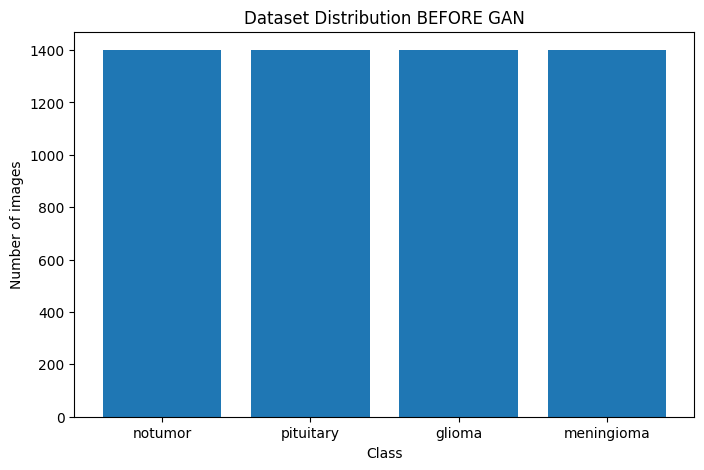

In [ ]:
plt.figure(figsize=(8,5))

plt.bar(before_counts.keys(), before_counts.values())

plt.title("Dataset Distribution BEFORE GAN")

plt.xlabel("Class")

plt.ylabel("Number of images")

plt.show()


### **Visualize sample MRI images BEFORE GAN**

In [ ]:
def show_sample_images(dataset_path, num_images=5):

    plt.figure(figsize=(12,6))

    i = 1

    for class_name in os.listdir(dataset_path):

        class_path = os.path.join(dataset_path, class_name)

        images = os.listdir(class_path)[:num_images]

        for img_name in images:

            img_path = os.path.join(class_path, img_name)

            img = cv2.imread(img_path)

            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

            plt.subplot(4, num_images, i)

            plt.imshow(img)

            plt.title(class_name)

            plt.axis("off")

            i += 1

    plt.show()


Sample images BEFORE GAN


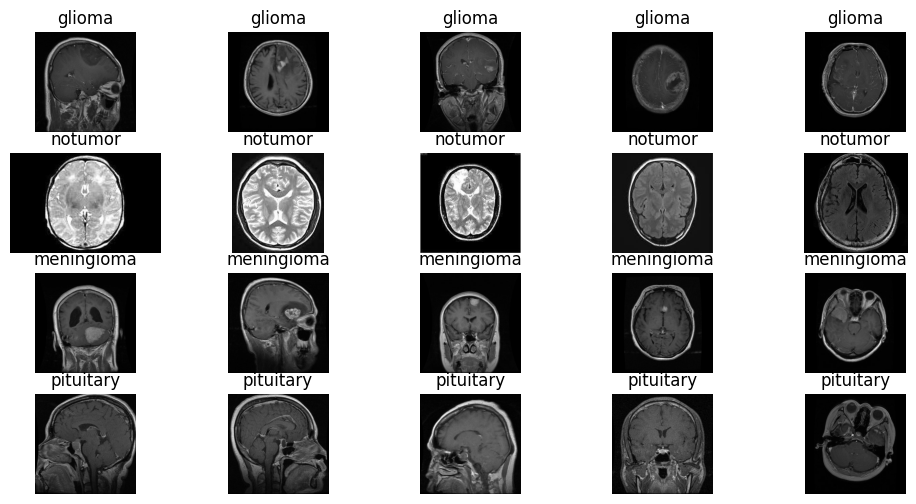

In [ ]:
print("Sample images BEFORE GAN")

show_sample_images(train_dataset_path)


### **Visualize generated synthetic images AFTER GAN**

In [ ]:
after_counts, after_total = get_dataset_shape(synthetic_dataset_path)

print("Dataset shape AFTER GAN:")
print(after_counts)
print("Total images:", after_total)


Dataset shape AFTER GAN:
{'notumor': 1500, 'pituitary': 1500, 'glioma': 1500, 'meningioma': 1500}
Total images: 6000


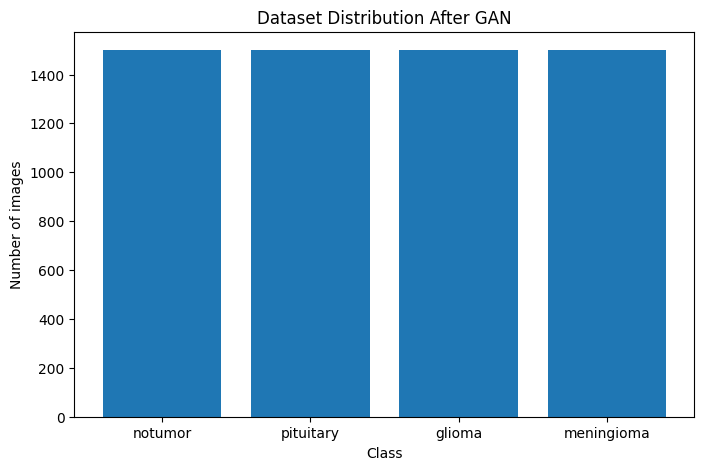

In [ ]:
plt.figure(figsize=(8,5))

plt.bar(after_counts.keys(), after_counts.values())

plt.title("Dataset Distribution After GAN")

plt.xlabel("Class")

plt.ylabel("Number of images")

plt.show()


Sample images After GAN


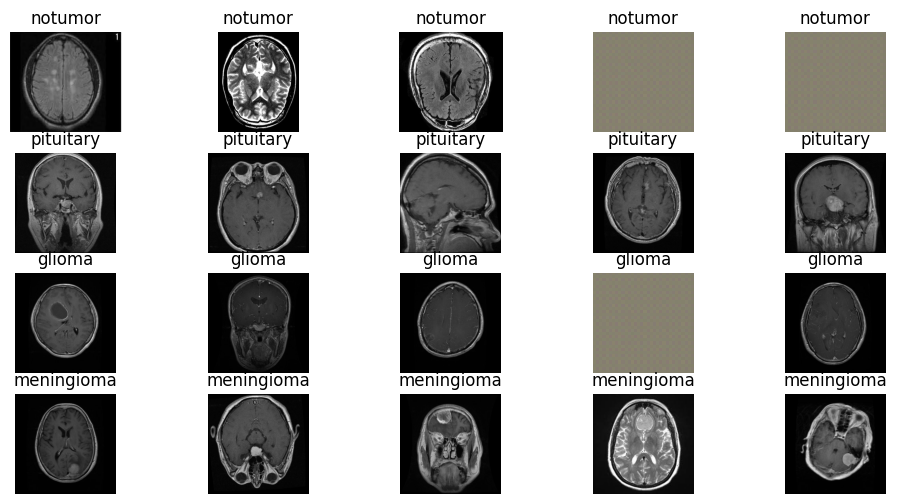

In [ ]:
print("Sample images After GAN")

show_sample_images(synthetic_dataset_path)


# **Brain Tumor Detection**

## **Dataset Preprocessing**

In [ ]:
#Dataset Preprocessing

# MRI images must be:

# • resized
# • normalized
# • converted to tensor

IMG_SIZE = 224
BATCH_SIZE = 32

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])


## **Load Dataset**

In [ ]:
#Load Dataset

train_dataset_path = '/content/dataset/Training'
test_dataset_path = '/content/dataset/Testing'


In [ ]:

train_dataset = datasets.ImageFolder(
    train_dataset_path,
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    test_dataset_path,
    transform=test_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

CLASS_NAMES = train_dataset.classes

NUM_CLASSES = len(CLASS_NAMES)

print("Classes:", CLASS_NAMES)
print("Number of classes:", NUM_CLASSES)


Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Number of classes: 4


## **Create CNN Model (ResNet50)**

In [ ]:
#Create CNN Model (ResNet50)

class CNNModel(nn.Module):

    def __init__(self, num_classes):

        super().__init__()

        self.model = timm.create_model(
            "resnet50",
            pretrained=True,
            num_classes=num_classes
        )

    def forward(self, x):

        return self.model(x)


## **Create Vision Transformer Model**

In [ ]:
#Create Vision Transformer Model


class ViTModel(nn.Module):

    def __init__(self, num_classes):

        super().__init__()

        self.model = timm.create_model(
            "vit_base_patch16_224",
            pretrained=True,
            num_classes=num_classes
        )

    def forward(self, x):

        return self.model(x)


## **Create Hybrid Model (CNN + Transformer)**

In [ ]:
#Create Hybrid Model (CNN + Transformer)

class HybridModel(nn.Module):

    def __init__(self, num_classes):

        super().__init__()

        self.cnn = timm.create_model(
            "resnet50",
            pretrained=True,
            num_classes=0
        )

        feature_size = self.cnn.num_features

        self.transformer = nn.TransformerEncoder(
            nn.TransformerEncoderLayer(
                d_model=feature_size,
                nhead=8
            ),
            num_layers=2
        )

        self.fc = nn.Linear(feature_size, num_classes)

    def forward(self, x):

        x = self.cnn(x)

        x = x.unsqueeze(0)

        x = self.transformer(x)

        x = x.squeeze(0)

        x = self.fc(x)

        return x


## **Training Function**

In [ ]:
#Training Function

def train_model(model, epochs=10):

    model.to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=0.0001
    )

    for epoch in range(epochs):

        model.train()

        total_loss = 0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            total_loss += loss.item()

            _, predicted = outputs.max(1)

            total += labels.size(0)

            correct += predicted.eq(labels).sum().item()

        accuracy = 100 * correct / total

        print(f"Epoch {epoch+1}: Loss={total_loss:.3f}, Accuracy={accuracy:.2f}%")

    return model


## **Evaluation Function**

In [ ]:
#Evaluation Function

def evaluate_model(model):

    model.eval()

    y_true = []
    y_pred = []

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(device)

            outputs = model(images)

            _, predicted = outputs.max(1)

            y_true.extend(labels.numpy())

            y_pred.extend(predicted.cpu().numpy())

    acc = accuracy_score(y_true, y_pred)

    print("Accuracy:", acc)

    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

    return acc


In [ ]:
#confusion matrix

from sklearn.metrics import confusion_matrix
import seaborn as sns

def plot_confusion_matrix(model, loader):

    model.eval()
    y_true = []
    y_pred = []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = model(images)
            _, predicted = outputs.max(1)
            y_true.extend(labels.numpy())
            y_pred.extend(predicted.cpu().numpy())
            # Compute confusion matrix
    cm = confusion_matrix(y_true, y_pred)

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title('Confusion Matrix')
    plt.show()


## **Train All Models**

In [ ]:
cnn = CNNModel(NUM_CLASSES)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

In [ ]:
vit = ViTModel(NUM_CLASSES)

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

In [ ]:
hybrid = HybridModel(NUM_CLASSES)

/tmp/ipykernel_1248/3211475220.py:17: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  self.transformer = nn.TransformerEncoder(


**Training All Models**

In [ ]:
print("Training CNN")
cnn = train_model(cnn, epochs=1)

Training CNN
Epoch 1: Loss=165.294, Accuracy=70.14%


In [ ]:
print("Training ViT")
vit = train_model(vit, epochs=1)


Training ViT


KeyboardInterrupt: 

In [ ]:
print("Training Hybrid")
hybrid = train_model(hybrid, epochs=1)


Training Hybrid
Epoch 1: Loss=97.262, Accuracy=79.09%


**Evaluation of all models**

In [ ]:
cnn_acc = evaluate_model(cnn)

Accuracy: 0.800625

Classification Report:
              precision    recall  f1-score   support

      glioma       0.93      0.59      0.72       400
  meningioma       0.66      0.74      0.70       400
     notumor       0.76      0.99      0.86       400
   pituitary       0.94      0.88      0.91       400

    accuracy                           0.80      1600
   macro avg       0.82      0.80      0.80      1600
weighted avg       0.82      0.80      0.80      1600



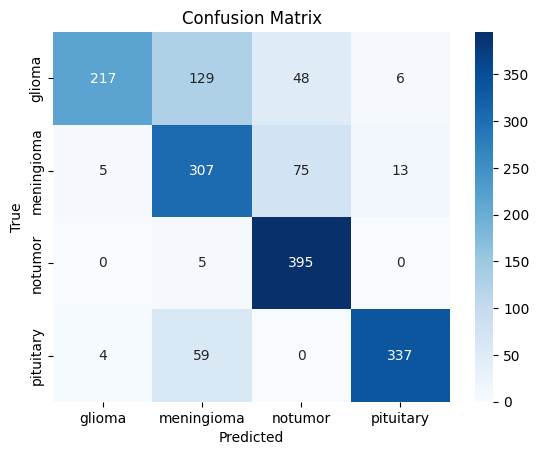

In [ ]:
plot_confusion_matrix(cnn, test_loader)

In [ ]:
vit_acc = evaluate_model(vit)

Accuracy: 0.91

Classification Report:
              precision    recall  f1-score   support

      glioma       0.90      0.81      0.85       400
  meningioma       0.93      0.86      0.89       400
     notumor       0.88      0.99      0.93       400
   pituitary       0.93      0.98      0.95       400

    accuracy                           0.91      1600
   macro avg       0.91      0.91      0.91      1600
weighted avg       0.91      0.91      0.91      1600



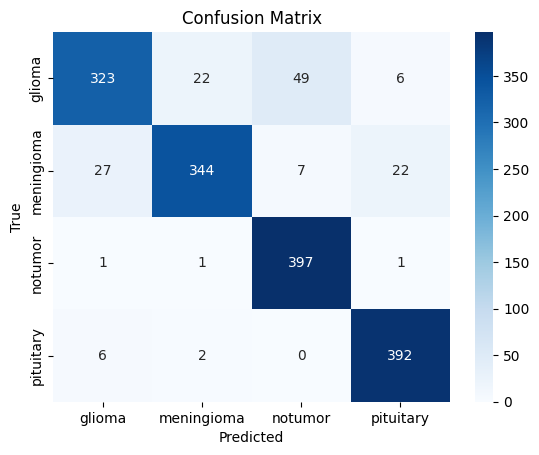

In [ ]:
plot_confusion_matrix(vit, test_loader)

In [ ]:
hybrid_acc = evaluate_model(hybrid)


Accuracy: 0.181875

Classification Report:
              precision    recall  f1-score   support

      glioma       0.14      0.12      0.13       400
  meningioma       0.28      0.25      0.26       400
     notumor       0.13      0.17      0.15       400
   pituitary       0.19      0.19      0.19       400

    accuracy                           0.18      1600
   macro avg       0.19      0.18      0.18      1600
weighted avg       0.19      0.18      0.18      1600



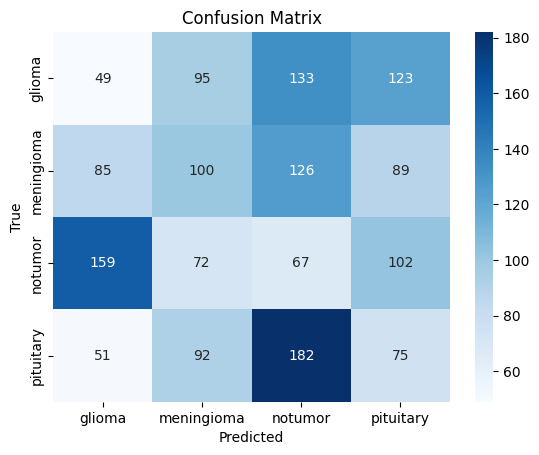

In [ ]:
plot_confusion_matrix(hybrid, test_loader)

## **Ensemble Model**

In [ ]:
def ensemble_predict(models, loader):

    y_true = []
    y_pred = []

    for images, labels in loader:

        images = images.to(device)

        preds = []

        for model in models:

            model.eval()

            with torch.no_grad():

                output = model(images)

                prob = torch.softmax(output, dim=1)

                preds.append(prob)

        avg_pred = torch.mean(torch.stack(preds), dim=0)

        _, predicted = avg_pred.max(1)

        y_true.extend(labels.numpy())
        y_pred.extend(predicted.cpu().numpy())

    acc = accuracy_score(y_true, y_pred)

    print("Ensemble Accuracy:", acc)

    return acc





In [ ]:
models = [cnn, vit, hybrid]



In [ ]:
ensemble_acc = ensemble_predict(models, test_loader)

Ensemble Accuracy: 0.904375


## **Save Models**

In [ ]:
# Create folder to save models
import os
os.makedirs("/content/drive/MyDrive/savedd_models", exist_ok=True)

In [ ]:
# Save model weights
torch.save(cnn.state_dict(), "/content/drive/MyDrive/savedd_models/cnn_model.pth")

In [ ]:
torch.save(vit.state_dict(), "/content/drive/MyDrive/savedd_models/vit_model.pth")

In [ ]:
torch.save(hybrid.state_dict(), "/content/drive/MyDrive/savedd_models/hybrid_model.pth")

In [ ]:

print("All models saved successfully.")

All models saved successfully.


## **Load ALL the Models**

In [ ]:
cnn= CNNModel(NUM_CLASSES)
cnn.load_state_dict(torch.load("/content/drive/MyDrive/savedd_models/cnn_model.pth"))
cnn.to(device) # Add this line to move the loaded model to the GPU
cnn.eval()

CNNModel(
  (model): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (act1): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): Bottleneck(
        (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (act1): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (drop_block): Identity()
        (act2): ReLU(inplace=True)
        (aa): Identity()
        (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn3): BatchNorm2d(256, eps=1e-05, momen

In [ ]:
vit = ViTModel(NUM_CLASSES)
vit.load_state_dict(torch.load("/content/drive/MyDrive/savedd_models/vit_model.pth"))
vit.eval()

In [ ]:
hybrid = HybridModel(NUM_CLASSES)
hybrid.load_state_dict(torch.load("/content/drive/MyDrive/savedd_models/hybrid_model.pth"))
hybrid.to(device)
hybrid.eval()

/tmp/ipykernel_1248/3211475220.py:17: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  self.transformer = nn.TransformerEncoder(


HybridModel(
  (cnn): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (act1): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): Bottleneck(
        (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (act1): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (drop_block): Identity()
        (act2): ReLU(inplace=True)
        (aa): Identity()
        (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn3): BatchNorm2d(256, eps=1e-05, mome

## **Predict New Image**

In [ ]:


def predict_image(image_path, model):

    transform = test_transform

    img = cv2.imread(image_path)

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Convert NumPy array to PIL Image
    img = Image.fromarray(img)

    img = transform(img)

    img = img.unsqueeze(0)

    img = img.to(device)

    model.eval()

    with torch.no_grad():

        output = model(img)

        prob = torch.softmax(output, dim=1)

        confidence, predicted = prob.max(1)

    class_name = CLASS_NAMES[predicted.item()]

    if class_name == "notumor":

        print("No Tumor")

    else:

        print("Tumor detected:", class_name)

    print("Confidence:", confidence.item())

In [ ]:
hybridoutput = predict_image("/content/menin.jpg", hybrid)
hybridoutput

Tumor detected: meningioma
Confidence: 0.3657783269882202


In [ ]:
cnnoutput = predict_image("/content/menin.jpg", cnn)
cnnoutput

Tumor detected: meningioma
Confidence: 0.6008573174476624


In [ ]:
vitoutput = predict_image("/content/menin.jpg", vit)
vitoutput

Tumor detected: meningioma
Confidence: 0.9426991939544678


In [ ]:
import collections

def ensemble_predict_single_image(image_path, models):
    transform = test_transform

    img = cv2.imread(image_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = Image.fromarray(img)
    img = transform(img)
    img = img.unsqueeze(0).to(device)

    individual_predictions = []
    all_model_probabilities = []

    for model in models:
        model.eval()
        with torch.no_grad():
            output = model(img)
            probabilities = torch.softmax(output, dim=1)
            _, predicted_class = probabilities.max(1)
            individual_predictions.append(predicted_class.item())
            all_model_probabilities.append(probabilities)

    # Majority Voting
    prediction_counts = collections.Counter(individual_predictions)
    final_predicted_class_idx = prediction_counts.most_common(1)[0][0]

    # Calculate average confidence for the final predicted class
    avg_probabilities = torch.mean(torch.stack(all_model_probabilities), dim=0)
    confidence = avg_probabilities[0, final_predicted_class_idx]

    class_name = CLASS_NAMES[final_predicted_class_idx]

    if class_name == "notumor":
        print("No Tumor detected.")
    else:
        print(f"Tumor detected: {class_name}")
    print(f"Confidence (for majority vote class): {confidence.item():.4f}")

In [ ]:
models = [cnn, vit, hybrid]
ensemble_predict_single_image("/content/menin.jpg", models)

Tumor detected: meningioma
Confidence (for majority vote class): 0.6364
